In [ ]:
!pip install torch-geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.9 MB/s  0:00:00


In [1]:
# Imports
import sys
from google.colab import drive
from pathlib import Path
import torch
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.graph_objects as go

import re
import json
import zipfile
import shutil

import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

from sklearn.metrics import roc_auc_score, average_precision_score
from IPython.display import display
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
# Mount drive and folders
drive.mount('/content/drive', force_remount=True)

FOLDER_NAME = 'cs5284_project'
PROJECT_DIR = Path(f'/content/drive/MyDrive/{FOLDER_NAME}')
DATA_DIR = PROJECT_DIR / "data"
SCRIPT_DIR = PROJECT_DIR / "scripts"

LOCAL_DATA_DIR = Path('/content/data')
LOCAL_DATA_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(SCRIPT_DIR.resolve()))

Mounted at /content/drive


In [3]:
# Read data
import utils

data = utils.load_data(DATA_DIR)

# Remove october 2022 from Delware due to incomplete month
df = data["DE"]["accidents"]
data["DE"]["accidents"] = df.loc[
    ~((df["year"] == 2022) & (df["month"] == 10))
].copy()
data["DE"]["nodes"].pop((2022, 10), None)

print("Delaware EDA coverage: January 2009–September 2022.")

KeyboardInterrupt: 

## Data Cleaning

Both states’ accident tables contain **no missing values or duplicate road-segment/month records**. However, weather features have substantial missing data: **38.8–67.7% in Delaware** and **61.5–74.3% in Maryland**. Average air pressure has the highest missingness in both states. Maryland has poorer coverage across every weather variable, so missing weather data will need to be addressed before modelling.

In [ ]:
labels = {
    "tavg": "Average temperature",
    "tmin": "Average daily minimum temperature",
    "tmax": "Average daily maximum temperature",
    "prcp": "Total monthly precipitation",
    "wspd": "Average wind speed",
    "pres": "Average air pressure",
    "node_id": "Node ID", "lat": "Latitude", "lon": "Longitude",
}

for state, d in data.items():
    print(f"\n{'Delaware' if state == 'DE' else 'Maryland'}")
    groups = {
        "Accidents": [d["accidents"]],
        "Node features (all months)": list(d["nodes"].values()),
    }
    for name, frames in groups.items():
        missing = pd.concat([df.isna().sum() for df in frames], axis=1).sum(axis=1)
        print(f"\n  {name} — missing values")
        if not missing.gt(0).any():
            print("    None")
        for column, count in missing[missing > 0].items():
            total = sum(len(df) for df in frames if column in df.columns)
            print(f"    {labels.get(column, column.replace('_', ' ').capitalize()):<36}"
                  f"{int(count):>10,} ({count / total:.1%})")

    duplicates = d["accidents"].duplicated(
        ["year", "month", "node_1_idx", "node_2_idx"]
    ).sum()
    print(f"\n  Duplicate road-segment/month records: {duplicates:,}")


Delaware

  Accidents — missing values
    None

  Node features (all months) — missing values
    Average temperature                  3,454,219 (42.7%)
    Average daily minimum temperature    3,139,501 (38.8%)
    Average daily maximum temperature    3,139,501 (38.8%)
    Total monthly precipitation          4,081,064 (50.5%)
    Average wind speed                   3,769,418 (46.6%)
    Average air pressure                 5,475,002 (67.7%)

  Duplicate road-segment/month records: 0

Maryland

  Accidents — missing values
    None

  Node features (all months) — missing values
    Average temperature                 14,840,346 (61.7%)
    Average daily minimum temperature   14,787,492 (61.5%)
    Average daily maximum temperature   14,787,492 (61.5%)
    Total monthly precipitation         16,603,717 (69.0%)
    Average wind speed                  16,768,441 (69.7%)
    Average air pressure                17,863,219 (74.3%)

  Duplicate road-segment/month records: 0


Both states have valid accident counts: all are finite, non-negative integers, with no missing or non-numeric entries. All month values fall between 1 and 12.

In [ ]:
for state, d in data.items():
    df = d["accidents"]
    counts = pd.to_numeric(df["acc_count"], errors="coerce")
    months = pd.to_numeric(df["month"], errors="coerce")

    print(f"\n{'Delaware' if state == 'DE' else 'Maryland'}")
    print(f"  Non-numeric or missing accident counts: {counts.isna().sum():,}")
    print(f"  Negative accident counts: {counts.lt(0).sum():,}")
    print(f"  Infinite accident counts: {counts.isin([float('inf'), -float('inf')]).sum():,}")
    print(f"  Fractional accident counts: {((counts % 1 != 0) & counts.notna() & ~counts.isin([float('inf'), -float('inf')])).sum():,}")
    print(f"  Invalid month values: {(~months.isin(range(1, 13))).sum():,}")


Delaware
  Non-numeric or missing accident counts: 0
  Negative accident counts: 0
  Infinite accident counts: 0
  Fractional accident counts: 0
  Invalid month values: 0

Maryland
  Non-numeric or missing accident counts: 0
  Negative accident counts: 0
  Infinite accident counts: 0
  Fractional accident counts: 0
  Invalid month values: 0


All accidents recorded are found in valid nodes and existing edges in the graph.

In [ ]:
for state, d in data.items():
    adj = d["adjacency"].coalesce()
    n = adj.shape[0]
    u, v = adj.indices()[:, adj.values() != 0].numpy()
    graph_edges = pd.Index(u * n + v)

    df = d["accidents"]
    a, b = df["node_1_idx"], df["node_2_idx"]
    valid = a.between(0, n - 1) & b.between(0, n - 1)
    matched = graph_edges.get_indexer(a[valid] * n + b[valid]) >= 0

    print(f"\n{'Delaware' if state == 'DE' else 'Maryland'}")
    print(f"  Accident records with node indices outside graph bounds: {(~valid).sum():,}")
    print(f"  Accident records within bounds but absent from graph: {(~matched).sum():,}")


Delaware
  Accident records with node indices outside graph bounds: 0
  Accident records within bounds but absent from graph: 0

Maryland
  Accident records with node indices outside graph bounds: 0
  Accident records within bounds but absent from graph: 0


In [ ]:
for state, d in data.items():
    adj = d["adjacency"].coalesce()
    n = adj.shape[0]
    uv = adj.indices()[:, adj.values() != 0]
    graph_keys = pd.Index((uv[0] * n + uv[1]).numpy())
    reference = next(iter(d["nodes"].values()))["node_id"]

    print(f"\n{'Delaware' if state == 'DE' else 'Maryland'}")
    print(f"  Months with incorrect node counts: {sum(len(df) != n for df in d['nodes'].values())}")
    print(f"  Months with duplicate node IDs: {sum(df.node_id.duplicated().any() for df in d['nodes'].values())}")
    print(f"  Months with different node ordering: {sum(not df.node_id.equals(reference) for df in d['nodes'].values())}")

    features = dict(d["edges"])
    features.update({f"{name} ({year})": t
                     for year, group in d["traffic"].items() for name, t in group.items()})
    issues = 0
    for name, t in features.items():
        if t.shape != adj.shape:
            print(f"  {name}: incorrect matrix dimensions")
            issues += 1
            continue
        t = t.to_sparse_coo().coalesce()
        uv = t.indices()[:, t.values() != 0]
        outside = (graph_keys.get_indexer((uv[0] * n + uv[1]).numpy()) < 0).sum()
        if outside:
            print(f"  {name}: {outside:,} nonzero entries outside graph")
            issues += 1
    print(f"  Feature matrices checked: {len(features)}; matrices with issues: {issues}")


Delaware
  Months with incorrect node counts: 0
  Months with duplicate node IDs: 0
  Months with different node ordering: 0
  Feature matrices checked: 27; matrices with issues: 0

Maryland
  Months with incorrect node counts: 0
  Months with duplicate node IDs: 0
  Months with different node ordering: 0
  Feature matrices checked: 30; matrices with issues: 0


In [ ]:
for state, d in data.items():
    df = d["accidents"]
    accident_months = pd.DatetimeIndex(
        pd.to_datetime(df[["year", "month"]].drop_duplicates().assign(day=1))
    ).sort_values()
    node_months = pd.DatetimeIndex([
        pd.Timestamp(y, m, 1) for y, m in d["nodes"]
    ]).sort_values()
    expected = pd.date_range(
        min(accident_months.min(), node_months.min()),
        max(accident_months.max(), node_months.max()), freq="MS"
    )

    print(f"\n{'Delaware' if state == 'DE' else 'Maryland'}")
    print(f"  Coverage checked: {expected.min():%Y-%m} to {expected.max():%Y-%m}")
    for name, months in [("Accident records", accident_months), ("Node-feature files", node_months)]:
        missing = expected.difference(months)
        print(f"  {name}: {len(months)} months present")
        print(f"    Missing months: {', '.join(missing.strftime('%Y-%m')) if len(missing) else 'None'}")


Delaware
  Coverage checked: 2009-01 to 2022-09
  Accident records: 165 months present
    Missing months: None
  Node-feature files: 165 months present
    Missing months: None

Maryland
  Coverage checked: 2015-01 to 2022-12
  Accident records: 96 months present
    Missing months: None
  Node-feature files: 96 months present
    Missing months: None


We will retain roads with missing weather or traffic information. Missing weather values will be imputed using training-period means. Traffic volumes will first be log-transformed, then imputed using the training-period mean in the transformed space. Both will be standardised using training-period statistics, with missingness indicators added to distinguish imputed values from observations. For years without traffic reports, we will carry forward the latest available earlier report. Delaware’s October 2022 will be excluded because its monthly node features are unavailable.

In [ ]:
for state, d in data.items():
    print(f"\n{'Delaware' if state == 'DE' else 'Maryland'}")
    issues = {}

    for df in d["nodes"].values():
        checks = {
            "Infinite weather values": df[["tavg", "tmin", "tmax", "prcp", "wspd", "pres"]].isin([float("inf"), -float("inf")]).sum().sum(),
            "Inconsistent temperatures": ((df.tmin > df.tavg) | (df.tavg > df.tmax) | (df.tmin > df.tmax)).sum(),
            "Negative precipitation": df.prcp.lt(0).sum(),
            "Negative wind speed": df.wspd.lt(0).sum(),
            "Non-positive air pressure": df.pres.le(0).sum(),
            "Invalid coordinates": (~df.lat.between(-90, 90) | ~df.lon.between(-180, 180)).sum(),
        }
        for name, count in checks.items():
            issues[name] = issues.get(name, 0) + int(count)

    features = {"Adjacency": d["adjacency"], **d["edges"]}
    features.update({f"Traffic volume ({year})": t
                     for year, group in d["traffic"].items() for t in group.values()})
    for name, t in features.items():
        values = t if t.layout == torch.strided else t.to_sparse_coo().coalesce().values()
        issues[f"{name}: missing/infinite values"] = int((~torch.isfinite(values)).sum())
        issues[f"{name}: negative values"] = int(values.lt(0).sum())

    problems = {name: count for name, count in issues.items() if count}
    for name, count in problems.items():
        print(f"  {name}: {count:,}")
    if not problems:
        print("  No issues found in the feature-validity checks.")


Delaware
  Traffic volume (2009): missing/infinite values: 115,524
  Traffic volume (2010): missing/infinite values: 115,523
  Traffic volume (2011): missing/infinite values: 115,523
  Traffic volume (2012): missing/infinite values: 115,523
  Traffic volume (2013): missing/infinite values: 115,523
  Traffic volume (2014): missing/infinite values: 114,971
  Traffic volume (2015): missing/infinite values: 114,966
  Traffic volume (2016): missing/infinite values: 114,967
  Traffic volume (2017): missing/infinite values: 114,966
  Traffic volume (2018): missing/infinite values: 115,103
  Traffic volume (2019): missing/infinite values: 115,086

Maryland
  Traffic volume (2012): missing/infinite values: 576,816
  Traffic volume (2013): missing/infinite values: 576,692
  Traffic volume (2014): missing/infinite values: 576,562
  Traffic volume (2015): missing/infinite values: 576,537
  Traffic volume (2016): missing/infinite values: 576,535
  Traffic volume (2017): missing/infinite values: 57

## Exploratory Data Analysis


The node counts, directed road-segment counts, and average and maximum degrees match the original paper for both states. Maryland’s average monthly accident count also matches at 9,149. Delaware’s average is 2,777 versus 2,763, partly reflecting our exclusion of October 2022; the small difference before exclusion remains unexplained.

Average segment length matches for Delaware (213 m), while Maryland differs slightly (212 m versus 211 m), potentially due to aggregation or preprocessing. Physical-road traffic coverage is close for Delaware (3.16% versus 3.14%) but lower for Maryland (1.40% versus 1.76%). Our coverage uses finite observations across all supplied years and unordered endpoint pairs; the paper’s precise calculation needs checking before attributing these differences to data quality.

In [ ]:
for state, d in data.items():
    adj = d["adjacency"].coalesce()
    n = adj.shape[0]
    u, v = adj.indices()[:, adj.values() != 0]
    edge_keys = pd.Index((u * n + v).numpy())
    road_keys = pd.Index((torch.minimum(u, v) * n + torch.maximum(u, v)).numpy()).unique()
    degree = torch.bincount(u, minlength=n)

    lengths = d["edges"]["length"]
    a, b = lengths._indices()
    values = lengths._values()
    valid = torch.isfinite(values) & torch.tensor(edge_keys.isin([])) if False else torch.isfinite(values)
    length_table = pd.DataFrame({
        "edge": (a * n + b)[valid].numpy(), "length": values[valid].numpy()
    }).groupby("edge")["length"].mean().reindex(edge_keys)

    observed = pd.Index([])
    for group in d["traffic"].values():
        t = group["AADT"]
        a, b = t._indices()[:, torch.isfinite(t._values())]
        observed = observed.union(pd.Index((a * n + b).numpy()))
    observed = edge_keys.intersection(observed)
    a, b = observed.to_numpy() // n, observed.to_numpy() % n
    covered_roads = pd.Index(a.clip(max=b) * n + a.clip(min=b)).unique()

    df = d["accidents"]
    monthly = df.groupby(["year", "month"])["acc_count"].sum()
    dates = pd.to_datetime([f"{y}-{m:02d}-01" for y, m in monthly.index])

    print(f"\n{'Delaware' if state == 'DE' else 'Maryland'}")
    print(f"  Period: {dates.min():%b %Y}–{dates.max():%b %Y}")
    print(f"  Nodes: {n:,}")
    print(f"  Directed road segments: {len(edge_keys):,}")
    print(f"  Physical roads (unordered endpoint pairs): {len(road_keys):,}")
    print(f"  Average accidents per month: {monthly.mean():,.0f}")
    print(f"  Average outgoing degree: {degree.float().mean():.1f}")
    print(f"  Maximum outgoing degree: {degree.max():,}")
    print(f"  Average directed segment length: {length_table.mean():,.0f} m")
    print(f"  Traffic coverage, directed (any year): {len(observed) / len(edge_keys):.2%}")
    print(f"  Traffic coverage, physical roads (any year): {len(covered_roads) / len(road_keys):.2%}")


Delaware
  Period: Jan 2009–Sep 2022
  Nodes: 49,023
  Directed road segments: 116,196
  Physical roads (unordered endpoint pairs): 65,252
  Average accidents per month: 2,777
  Average outgoing degree: 2.4
  Maximum outgoing degree: 6
  Average directed segment length: 213 m
  Traffic coverage, directed (any year): 1.77%
  Traffic coverage, physical roads (any year): 3.16%

Maryland
  Period: Jan 2015–Dec 2022
  Nodes: 250,565
  Directed road segments: 580,526
  Physical roads (unordered endpoint pairs): 317,281
  Average accidents per month: 9,149
  Average outgoing degree: 2.3
  Maximum outgoing degree: 8
  Average directed segment length: 212 m
  Traffic coverage, directed (any year): 0.76%
  Traffic coverage, physical roads (any year): 1.40%


Monthly accident counts fluctuate in both states, with Maryland recording substantially more accidents than Delaware. Delaware shows an overall increase over time, while Maryland’s pre-2020 totals are relatively stable. We hypothesize that the data recorded in the beginning for Delware is increasing as they might have just started collecting traffic data. Both states experience a sharp decline around early 2020, followed by a recovery. This likely reflects reduced road travel during COVID-19 restrictions, although the plot alone cannot establish the cause. Because this disruption occurs in the test period, it may make predictions during that period less accurate.

Monthly accident counts suggest seasonality, with higher averages toward the end of the year. Holiday-related travel may contribute to this pattern, with major holidays like Thanksgiving and Christmas that may warrant more travelling.

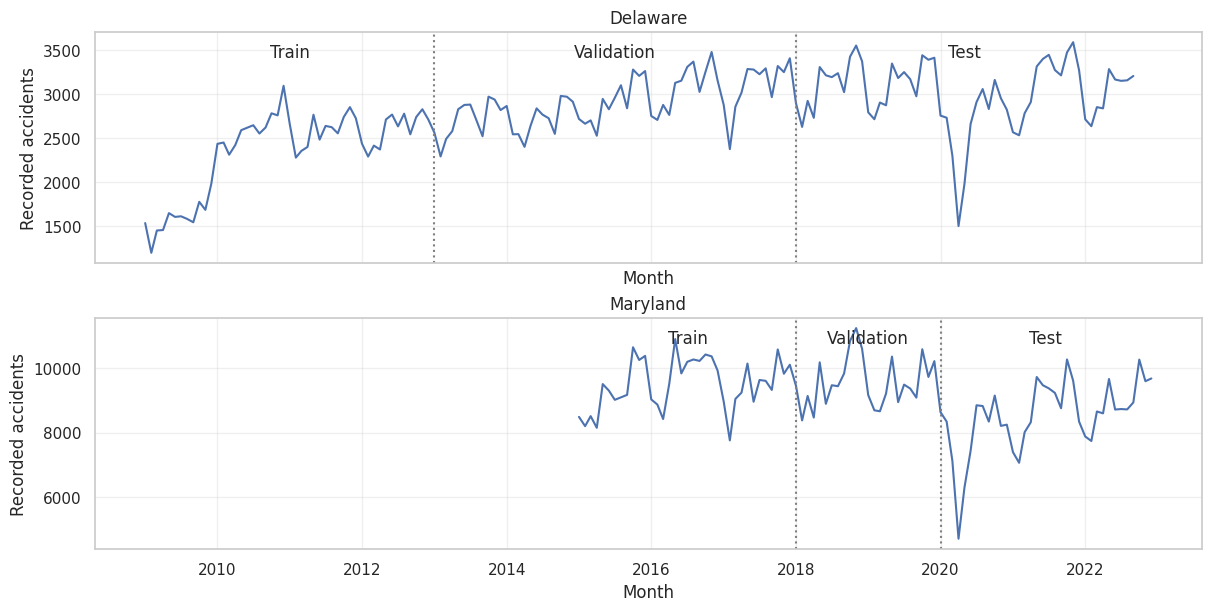

In [ ]:
# Monthly accidents total
fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout="constrained", sharex=True)

for ax, (state, val_year, test_year) in zip(
    axes, [("DE", 2013, 2018), ("MD", 2018, 2020)]
):
    monthly = data[state]["accidents"].groupby(["year", "month"])["acc_count"].sum()
    dates = pd.to_datetime([f"{y}-{m:02d}-01" for y, m in monthly.index])
    val, test = pd.Timestamp(val_year, 1, 1), pd.Timestamp(test_year, 1, 1)

    ax.plot(dates, monthly.values)
    ax.axvline(val, color="grey", linestyle=":")
    ax.axvline(test, color="grey", linestyle=":")

    for label, start, end in [
        ("Train", dates.min(), val),
        ("Validation", val, test),
        ("Test", test, dates.max()),
    ]:
        ax.text(start + (end - start) / 2, 0.95, label,
                transform=ax.get_xaxis_transform(), ha="center", va="top")

    ax.set(title="Delaware" if state == "DE" else "Maryland",
           xlabel="Month", ylabel="Recorded accidents")
    ax.grid(alpha=0.3)

plt.show()

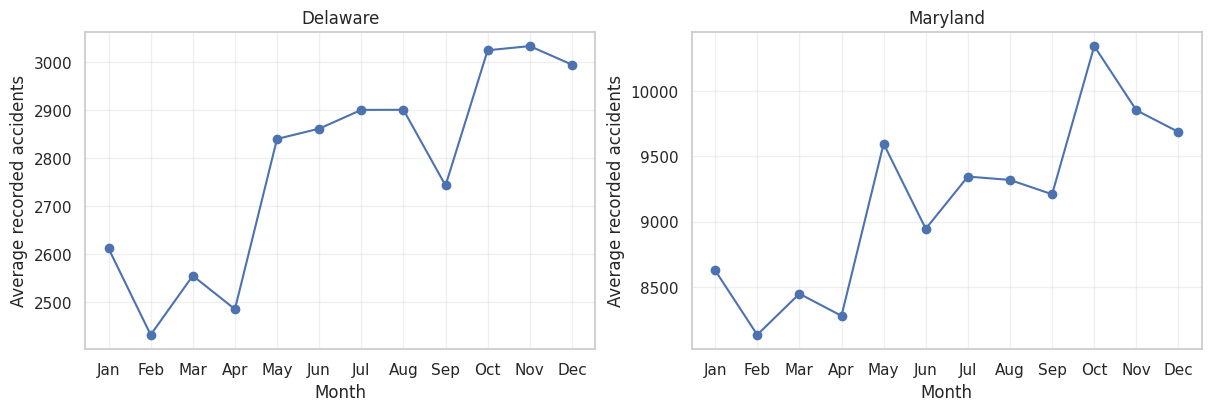

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for ax, state in zip(axes, ["DE", "MD"]):
    monthly = data[state]["accidents"].groupby(["year", "month"])["acc_count"].sum()
    seasonal = monthly.groupby("month").mean()

    ax.plot(seasonal.index, seasonal.values, marker="o")
    ax.set(title="Delaware" if state == "DE" else "Maryland",
           xlabel="Month", ylabel="Average recorded accidents",
           xticks=range(1, 13),
           xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    ax.grid(alpha=0.3)

plt.show()

A **road-month** represents one physical road observed over one month. Opposite directions sharing the same endpoints are combined into a single road, consistent with the baseline models.

Delaware contains approximately **10.77 million road-months**, of which **96.52%** have zero recorded accidents. Maryland contains **30.46 million road-months**, with **97.61%** recording zero accidents. Mean accident counts are **0.0426** and **0.0288** per road-month, respectively. This sparsity means a model predicting zero everywhere could achieve a low MAE, making accident-detection and high-risk-road metrics important alongside count accuracy.


Delaware
  Road-months: 10,766,580
  Zero accidents: 96.52%
  Mean accidents per road-month: 0.0426

Maryland
  Road-months: 30,458,976
  Zero accidents: 97.61%
  Mean accidents per road-month: 0.0288


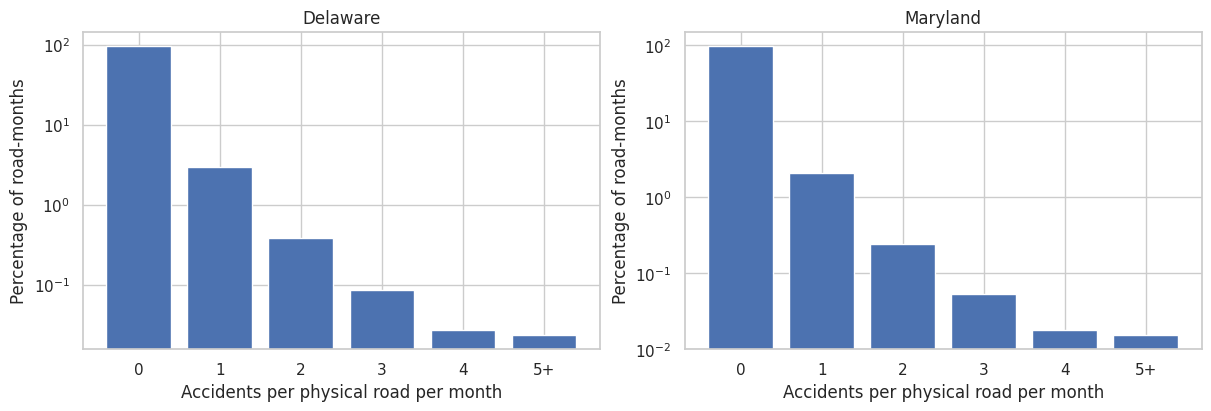

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for ax, state in zip(axes, ["DE", "MD"]):
    d = data[state]
    adj = d["adjacency"].coalesce()
    u, v = adj.indices()[:, adj.values() != 0]
    n = adj.shape[0]
    roads = pd.Index((torch.minimum(u, v) * n + torch.maximum(u, v)).numpy()).unique()

    df = d["accidents"].copy()
    a, b = df["node_1_idx"], df["node_2_idx"]
    df["road"] = a.where(a <= b, b) * n + a.where(a >= b, b)
    counts = df.groupby(["year", "month", "road"])["acc_count"].sum()
    months = df[["year", "month"]].drop_duplicates().shape[0]
    total = len(roads) * months
    positive = counts[counts > 0]
    zero = total - len(positive)
    frequencies = [
        zero, positive.eq(1).sum(), positive.eq(2).sum(),
        positive.eq(3).sum(), positive.eq(4).sum(), positive.ge(5).sum()
    ]

    ax.bar(["0", "1", "2", "3", "4", "5+"], [100 * x / total for x in frequencies])
    ax.set(title="Delaware" if state == "DE" else "Maryland",
           xlabel="Accidents per physical road per month",
           ylabel="Percentage of road-months", yscale="log")
    print(f"\n{ax.get_title()}")
    print(f"  Road-months: {total:,}")
    print(f"  Zero accidents: {zero / total:.2%}")
    print(f"  Mean accidents per road-month: {positive.sum() / total:.4f}")

plt.show()

Accidents are concentrated on a small proportion of roads in both states. The top 1% of roads account for 24.0% of accidents in Delaware and 26.8% in Maryland. These shares rise to 70.6% and 73.6%, respectively, for the top 10% of roads. Concentration is slightly stronger in Maryland.


Delaware
  Top 1% of roads: 24.0% of accidents
  Top 5% of roads: 53.6% of accidents
  Top 10% of roads: 70.6% of accidents

Maryland
  Top 1% of roads: 26.8% of accidents
  Top 5% of roads: 56.9% of accidents
  Top 10% of roads: 73.6% of accidents


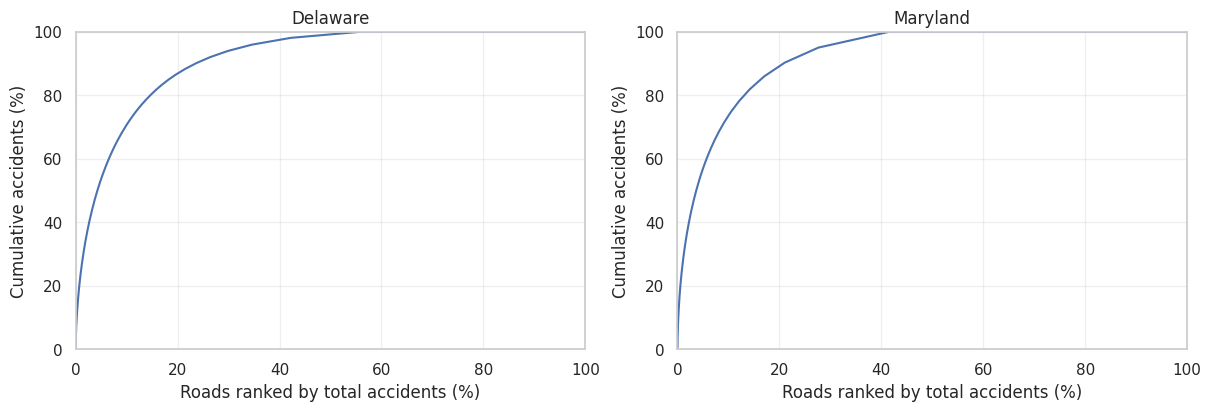

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for ax, state in zip(axes, ["DE", "MD"]):
    d = data[state]
    adj = d["adjacency"].coalesce()
    u, v = adj.indices()[:, adj.values() != 0]
    n = adj.shape[0]
    roads = pd.Index((torch.minimum(u, v) * n + torch.maximum(u, v)).numpy()).unique()

    df = d["accidents"].copy()
    a, b = df["node_1_idx"], df["node_2_idx"]
    df["road"] = a.where(a <= b, b) * n + a.where(a >= b, b)
    totals = df.groupby("road")["acc_count"].sum().reindex(roads, fill_value=0)
    totals = totals.sort_values(ascending=False)
    cumulative = totals.cumsum() / totals.sum() * 100

    ax.plot([0] + [100 * i / len(totals) for i in range(1, len(totals) + 1)],
            [0] + cumulative.tolist())
    ax.set(title="Delaware" if state == "DE" else "Maryland",
           xlabel="Roads ranked by total accidents (%)",
           ylabel="Cumulative accidents (%)", xlim=(0, 100), ylim=(0, 100))
    ax.grid(alpha=0.3)

    print(f"\n{ax.get_title()}")
    for pct in [1, 5, 10]:
        k = max(1, int(len(totals) * pct / 100))
        print(f"  Top {pct}% of roads: {cumulative.iloc[k - 1]:.1f}% of accidents")

plt.show()

Historical persistence measures whether roads recording an accident in one month are more likely to record another in the following month.

In Delaware, the next-month accident probability is 23.37% after an accident month, compared with 2.77% after a zero-accident month—an 8.4-fold difference. Maryland shows probabilities of 19.81% and 1.97%, respectively, a 10.1-fold difference.

These results support investigating accident history as a predictive feature. However, the association may partly reflect persistent road characteristics, such as traffic exposure and road layout.

In [ ]:
for state, d in data.items():
    adj = d["adjacency"].coalesce()
    u, v = adj.indices()[:, adj.values() != 0]
    n = adj.shape[0]
    n_roads = pd.Index((torch.minimum(u, v) * n + torch.maximum(u, v)).numpy()).nunique()

    df = d["accidents"].copy()
    a, b = df["node_1_idx"], df["node_2_idx"]
    df["road"] = a.where(a <= b, b) * n + a.where(a >= b, b)
    df["date"] = pd.to_datetime(df[["year", "month"]].assign(day=1))
    months = {
        date: set(group.loc[group.acc_count > 0, "road"])
        for date, group in df.groupby("date")
    }

    repeat = previous_positive = new = previous_zero = 0
    for date, current in sorted(months.items()):
        previous_date = date - pd.offsets.MonthBegin(1)
        if previous_date not in months:
            continue
        previous = months[previous_date]
        repeat += len(previous & current)
        previous_positive += len(previous)
        new += len(current - previous)
        previous_zero += n_roads - len(previous)

    p_repeat = repeat / previous_positive
    p_new = new / previous_zero
    print(f"\n{'Delaware' if state == 'DE' else 'Maryland'}")
    print(f"  Next-month accident probability after an accident month: {p_repeat:.2%}")
    print(f"  Next-month accident probability after a zero-accident month: {p_new:.2%}")
    print(f"  Relative likelihood: {p_repeat / p_new:.1f}×")


Delaware
  Next-month accident probability after an accident month: 23.37%
  Next-month accident probability after a zero-accident month: 2.77%
  Relative likelihood: 8.4×

Maryland
  Next-month accident probability after an accident month: 19.81%
  Next-month accident probability after a zero-accident month: 1.97%
  Relative likelihood: 10.1×


Roads’ historical accident counts show a positive association with those of neighbouring roads. The correlation between log-transformed mean monthly accident counts is 0.538 in Delaware and 0.556 in Maryland, suggesting that roads with higher accident counts tend to share intersections with other higher-count roads.

Delaware: correlation = 0.538
Maryland: correlation = 0.556


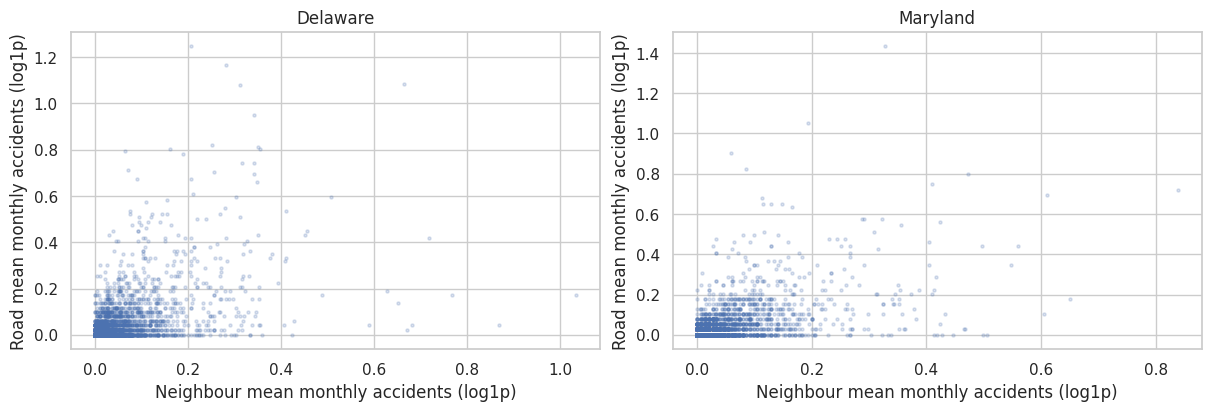

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for ax, (state, end_year) in zip(axes, [("DE", 2012), ("MD", 2017)]):
    d = data[state]
    adj = d["adjacency"].coalesce()
    n = adj.shape[0]
    u, v = adj.indices()[:, adj.values() != 0]
    roads = (torch.minimum(u, v) * n + torch.maximum(u, v)).unique()
    a, b = roads // n, roads % n

    df = d["accidents"].query("year <= @end_year").copy()
    x, y = df["node_1_idx"], df["node_2_idx"]
    df["road"] = x.where(x <= y, y) * n + x.where(x >= y, y)
    months = df[["year", "month"]].drop_duplicates().shape[0]
    risk = torch.tensor(
        df.groupby("road").acc_count.sum().reindex(roads.numpy(), fill_value=0).to_numpy(),
        dtype=torch.float64
    ) / months

    # Exclude self-loops so each road has two distinct endpoints.
    keep = a != b
    a, b, risk = a[keep], b[keep], risk[keep]
    degree = torch.bincount(torch.cat([a, b]), minlength=n)
    totals = torch.zeros(n, dtype=risk.dtype)
    totals.index_add_(0, a, risk)
    totals.index_add_(0, b, risk)
    neighbours = degree[a] + degree[b] - 2
    valid = neighbours > 0
    neighbour_risk = (totals[a] + totals[b] - 2 * risk)[valid] / neighbours[valid]

    points = pd.DataFrame({
        "road": risk[valid].log1p().numpy(),
        "neighbours": neighbour_risk.log1p().numpy()
    })
    sample = points.sample(min(5000, len(points)), random_state=0)
    ax.scatter(sample["neighbours"], sample["road"], s=5, alpha=0.2)
    ax.set(title="Delaware" if state == "DE" else "Maryland",
           xlabel="Neighbour mean monthly accidents (log1p)",
           ylabel="Road mean monthly accidents (log1p)")
    print(f"{ax.get_title()}: correlation = {points.corr().iloc[0, 1]:.3f}")

plt.show()

Mean monthly accident counts generally increase with road length in both states. This supports retaining road length as a predictive feature.

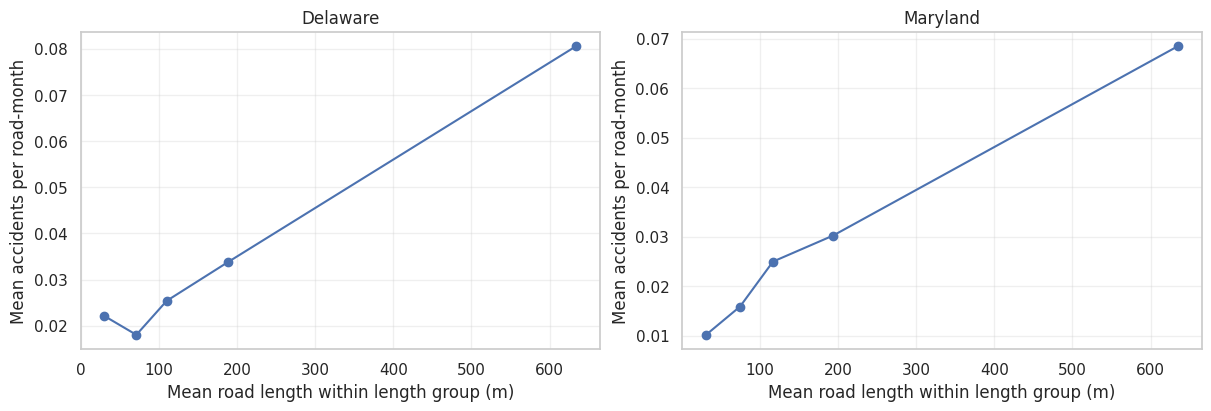

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for ax, (state, end_year) in zip(axes, [("DE", 2012), ("MD", 2017)]):
    d = data[state]
    adj = d["adjacency"].coalesce()
    n = adj.shape[0]
    u, v = adj.indices()[:, adj.values() != 0]
    roads = pd.Index((torch.minimum(u, v) * n + torch.maximum(u, v)).numpy()).unique()

    t = d["edges"]["length"]
    a, b = t._indices()
    values = t._values()
    valid = torch.isfinite(values)
    lengths = pd.DataFrame({
        "road": (torch.minimum(a, b) * n + torch.maximum(a, b))[valid].numpy(),
        "length": values[valid].numpy()
    }).groupby("road")["length"].mean()

    df = d["accidents"].query("year <= @end_year").copy()
    a, b = df.node_1_idx, df.node_2_idx
    df["road"] = a.where(a <= b, b) * n + a.where(a >= b, b)
    months = df[["year", "month"]].drop_duplicates().shape[0]
    summary = pd.DataFrame({
        "length": lengths.reindex(roads),
        "accidents": df.groupby("road").acc_count.sum().reindex(roads, fill_value=0) / months
    }).dropna()
    summary = summary[summary.length > 0]
    summary["group"] = pd.qcut(summary.length, 5, duplicates="drop")
    grouped = summary.groupby("group", observed=True).agg(
        length=("length", "mean"), accidents=("accidents", "mean")
    )

    ax.plot(grouped.length, grouped.accidents, marker="o")
    ax.set(title="Delaware" if state == "DE" else "Maryland",
           xlabel="Mean road length within length group (m)",
           ylabel="Mean accidents per road-month")
    ax.grid(alpha=0.3)

plt.show()

Mean monthly accident counts vary substantially by road type. Motorways have the highest counts in both states, followed by trunk and primary roads, while residential and unclassified roads have much lower counts. The broadly similar ordering across states supports retaining road category as a predictive feature.

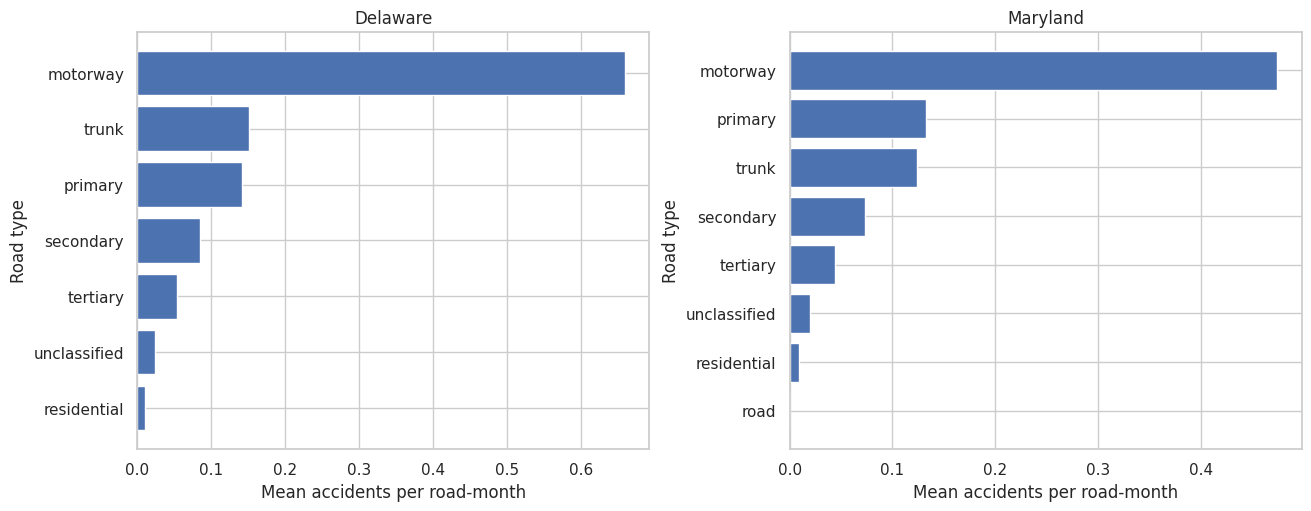

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

for ax, (state, end_year) in zip(axes, [("DE", 2012), ("MD", 2017)]):
    d = data[state]
    n = d["adjacency"].shape[0]
    categories = {}
    for name, t in d["edges"].items():
        if name in ["length", "oneway"]:
            continue
        a, b = t._indices()
        values = t._values()
        keep = torch.isfinite(values) & (values > 0)
        keys = (torch.minimum(a, b) * n + torch.maximum(a, b))[keep].numpy()
        categories[name] = pd.Series(1, index=pd.Index(keys).unique())

    flags = pd.DataFrame(categories).fillna(0)
    # Use only roads with one unambiguous category.
    types = flags.loc[flags.sum(axis=1) == 1].idxmax(axis=1)

    df = d["accidents"].query("year <= @end_year").copy()
    a, b = df.node_1_idx, df.node_2_idx
    df["road"] = a.where(a <= b, b) * n + a.where(a >= b, b)
    months = df[["year", "month"]].drop_duplicates().shape[0]
    summary = pd.DataFrame({
        "type": types,
        "accidents": df.groupby("road").acc_count.sum().reindex(types.index, fill_value=0) / months
    })
    grouped = summary.groupby("type").agg(
        roads=("accidents", "size"), accidents=("accidents", "mean")
    ).query("roads >= 100").sort_values("accidents")

    ax.barh(grouped.index.str.replace("_", " "), grouped.accidents)
    ax.set(title="Delaware" if state == "DE" else "Maryland",
           xlabel="Mean accidents per road-month", ylabel="Road type")

plt.show()

Weather coverage is incomplete and varies substantially over time. Maryland has particularly low availability before 2021, while Delaware’s air-pressure observations are almost entirely unavailable during 2015–2018. Both states show improved coverage in 2021–2022, creating different missingness patterns between training and testing.

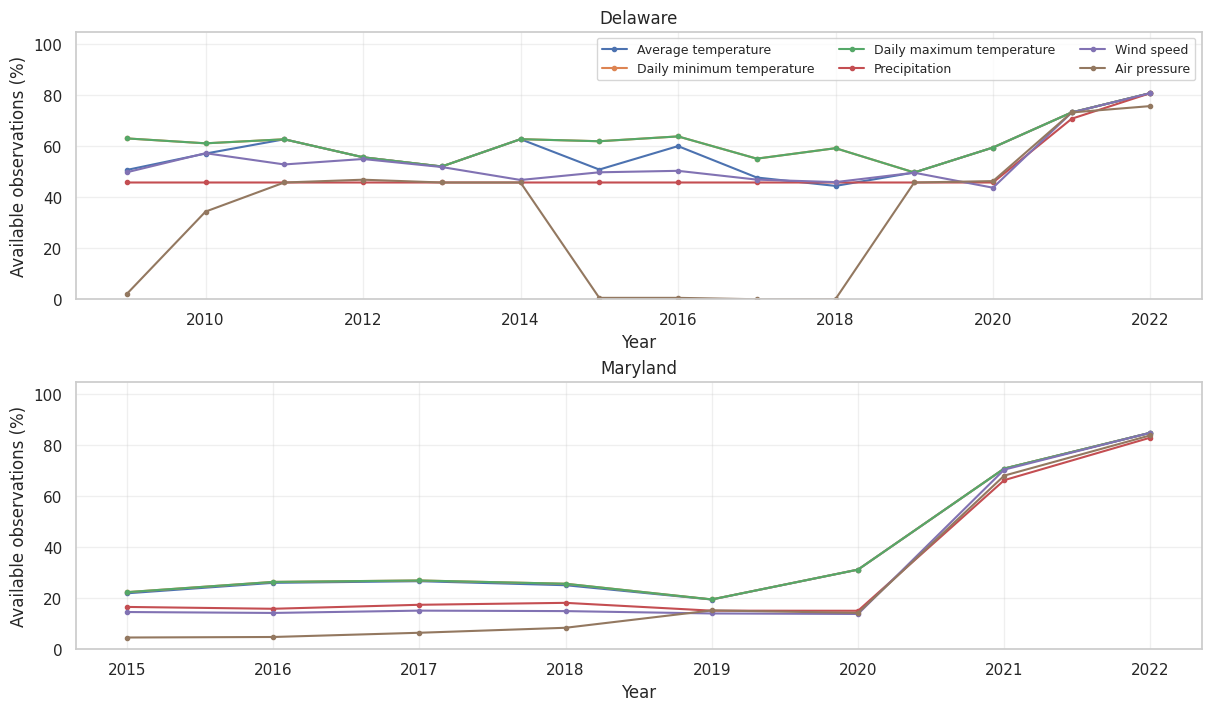

In [ ]:
labels = {
    "tavg": "Average temperature",
    "tmin": "Daily minimum temperature",
    "tmax": "Daily maximum temperature",
    "prcp": "Precipitation",
    "wspd": "Wind speed",
    "pres": "Air pressure",
}
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")

for ax, state in zip(axes, ["DE", "MD"]):
    rows = []
    for (year, month), df in data[state]["nodes"].items():
        rows.append({"year": year, **df[list(labels)].notna().sum().to_dict(),
                     "observations": len(df)})
    annual = pd.DataFrame(rows).groupby("year").sum()
    coverage = annual[list(labels)].div(annual["observations"], axis=0) * 100

    for column, label in labels.items():
        ax.plot(coverage.index, coverage[column], marker=".", label=label)
    ax.set(title="Delaware" if state == "DE" else "Maryland",
           xlabel="Year", ylabel="Available observations (%)", ylim=(0, 105))
    ax.grid(alpha=0.3)

axes[0].legend(ncol=3, fontsize=9)
plt.show()

## Interactive Visualisation

In [4]:
import risk_map

risk_map.show_risk_map(PROJECT_DIR)

DE: longitude -75.556, latitude 39.238
MD: longitude -76.776, latitude 39.095


<IPython.core.display.Javascript object>

Saved standalone application: /content/drive/MyDrive/cs5284_project/road_safety_explorer.html


PosixPath('/content/drive/MyDrive/cs5284_project/road_safety_explorer.html')